# Public notebook copy

Published from the author's course-project archive. Student identifiers and private paths have been removed; paths now use bundled repository data. Known attribution, numbering, distribution-framing and stale summary errors were corrected. The original private files are unchanged.

Saved outputs below are historical snapshots, not a new execution. Rerun for outputs matching the updated explanatory text.

The GPU inference notebook is still missing. These notebooks document the project or analyze precomputed scores. See the repository README for current results and scope.


# F-chelsea-zhao-1: Data Preparation

**MIE1512 Course Project — Final Submission**
Author: Chelsea Zhao


## Table of Contents

1. [Environment Setup](#1-environment-setup)
2. [Load ProcessBench](#2-load-processbench)
3. [Exploratory Data Analysis](#3-exploratory-data-analysis)
4. [Stratified Sample Construction](#4-stratified-sample-construction)
5. [Save Sample to Parquet](#5-save-sample-to-parquet)


## Time Reporting

| Section | Task | Hours |
|---------|------|-------|
| 1 — Environment Setup | Dependency install, CUDA verify, import verify | 0.5h |
| 2 — Load ProcessBench | Data loading pipeline, local parquet cache | 1.5h |
| 3 — EDA | Generator distribution, step counts, error rates, heatmap | 1.5h |
| 4 — Stratified Sample | Sampling algorithm, fallback logic, validation | 1.0h |
| 5 — Save Parquet | Parquet export for Notebook 2 (analysis) | 0.5h (included above) |
| **Total (this notebook)** | | **4.5h** |


## Environment and paths

Use Open in Colab, or run from a cloned repository. The bootstrap reads bundled F-data/ inputs and writes outputs to generated-results/. No private Drive mount is needed.


In [1]:
%pip install -q pandas numpy pyarrow matplotlib seaborn scikit-learn


Dependencies ready (CPU-only, Parquet IO).


In [2]:
# Find the repository data locally, or clone this public repository in Colab.
from pathlib import Path
import os, sys, subprocess

BASE_PATH = Path.cwd()
if not (BASE_PATH / 'F-data').is_dir():
    BASE_PATH = next((p for p in Path.cwd().parents if (p / 'F-data').is_dir()), BASE_PATH)
if not (BASE_PATH / 'F-data').is_dir() and 'google.colab' in sys.modules:
    BASE_PATH = Path('/content/mie1512-reasoneval-portfolio')
    if not BASE_PATH.exists():
        subprocess.run(['git', 'clone', 'https://github.com/rulangyuezhao-cmd/mie1512-reasoneval-portfolio.git', str(BASE_PATH)], check=True)
assert (BASE_PATH / 'F-data').is_dir(), 'Run from a repository checkout, or use Open in Colab.'
DATA_DIR = str(BASE_PATH / 'F-data')
RESULTS_DIR = str(BASE_PATH / 'generated-results')
os.makedirs(RESULTS_DIR, exist_ok=True)
PARQUET_PATH = os.path.join(DATA_DIR, 'processbench_cached.parquet')
SAMPLE_PATH = os.path.join(RESULTS_DIR, 'processbench_sample.parquet')
RESULTS_CSV = os.path.join(DATA_DIR, 'processbench_full_results.parquet')
FIG_PREFIX = 'full_'
print('Bundled inputs:', sorted(os.listdir(DATA_DIR)))
print('Generated files will be saved under generated-results/.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_PATH = [private Drive path removed]
DATA_DIR  = [private Drive path removed]
Files in F-data: ['06_eda_combined.png', 'full_figure1_step_example_cards.png', 'full_figure2_acc_vs_auc.png', 'full_figure3_score_distributions.png', 'full_figure4_acc_vs_fpr.png', 'full_table4_fpr.csv', 'processbench_08_results.csv', 'processbench_cached.parquet', 'processbench_full_results.parquet', 'processbench_sample.parquet']


In [3]:
import os, time, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import defaultdict
from matplotlib.lines import Line2D

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

os.makedirs(RESULTS_DIR, exist_ok=True)
print('Imports OK. Writing outputs to:', RESULTS_DIR)

Imports OK. Writing outputs to: [private Drive path removed]


---

## 2. Load ProcessBench

ProcessBench contains 3,400 human-annotated solutions from 12 open-source generators across four difficulty subsets. Each solution has a `label` field: the 0-indexed position of the first erroneous step, or −1 if all steps are correct.

### Dataset Selection Rationale

Evaluating ReasonEval's step-level validity scoring requires datasets with **human-annotated step-level labels**. Such datasets are extremely rare — human step-level annotation is labor-intensive and requires annotators with strong mathematical background.

| Dataset | Size | Labels | Decision |
|---------|------|--------|----------|
| **ProcessBench** | 3,400 | ✅ Human (first error step) | ✅ **Selected** |
| PRM800K / MR-MATH / MR-GSM8K | 800K | ✅ Human | ❌ Used by original paper |
| MathShepherd | 444K | ❌ LLM (MC estimation) | ❌ Rejected — 28.2% non-monotonic labels |
| NuminaMath-CoT | 850K | ❌ No step labels | ❌ Cannot compute F1 / AUC |
| OpenMathInstruct-1/2 | 1.8M–14M | ❌ No step labels | ❌ Instruction tuning format only |

**Key difference vs. original paper datasets:** ProcessBench's GSM8K and MATH subsets use **different solution generators** than MR-GSM8K and MR-MATH — overlap with the paper's training or evaluation examples has not been established.

### 2.1 Load ProcessBench from the Cached Parquet

For Colab reproducibility the grader reads the frozen `processbench_cached.parquet` from `F-data/`. The original pipeline (V1) downloaded `Qwen/ProcessBench` from HuggingFace on first run and wrote this cache; that step is not re-performed here so the notebook is offline, deterministic, and CPU-only.


In [4]:
# Load the full ProcessBench dataset from the cached Parquet in F-data.
# The original local pipeline (V1) downloaded from HuggingFace on first run
# and wrote this file; for Colab reproducibility we treat the cached Parquet
# as authoritative so the notebook runs offline and deterministically.
df_pb = pd.read_parquet(PARQUET_PATH)

# Re-derive convenience columns idempotently (cheap, guards against older caches).
if 'has_error' not in df_pb.columns:
    df_pb['has_error'] = (df_pb['label'] >= 0).astype(int)
if 'n_steps' not in df_pb.columns:
    df_pb['n_steps'] = df_pb['steps'].apply(len)
if 'problem_len' not in df_pb.columns:
    df_pb['problem_len'] = df_pb['problem'].apply(len)
if 'solution_len' not in df_pb.columns:
    df_pb['solution_len'] = df_pb['steps'].apply(lambda x: sum(len(s) for s in x))

print(f'Loaded: {len(df_pb):,} rows from {PARQUET_PATH}')
print(df_pb.groupby('subset')[['has_error', 'n_steps']].mean().round(2))

Loaded: 3,400 rows from [private Drive path removed]
               has_error  n_steps
subset                           
gsm8k               0.52     5.20
math                0.59     6.50
olympiadbench       0.66     8.82
omnimath            0.76     8.29


---

## 3. Exploratory Data Analysis

Dataset characterised along three dimensions before inference: step count distribution, problem/solution length, and error rate per subset × generator.

### 3.1 Define Generator Metadata

Maps each generator model to its family, parameter count, and plot colour for consistent visualisation across all figures.

In [5]:
GENERATOR_META = {
    'Meta-Llama-3-8B-Instruct':    {'family': 'Llama-3',      'size': 8,   'color': '#1F4E79'},
    'Meta-Llama-3-70B-Instruct':   {'family': 'Llama-3',      'size': 70,  'color': '#1F4E79'},
    'Llama-3.1-8B-Instruct':       {'family': 'Llama-3.1',    'size': 8,   'color': '#4C72B0'},
    'Llama-3.1-70B-Instruct':      {'family': 'Llama-3.1',    'size': 70,  'color': '#4C72B0'},
    'Qwen2-1.5B-Instruct':         {'family': 'Qwen2',        'size': 1.5, 'color': '#DD8452'},
    'Qwen2-7B-Instruct':           {'family': 'Qwen2',        'size': 7,   'color': '#DD8452'},
    'Qwen2-72B-Instruct':          {'family': 'Qwen2',        'size': 72,  'color': '#DD8452'},
    'Qwen2.5-1.5B-Instruct':       {'family': 'Qwen2.5',      'size': 1.5, 'color': '#55A868'},
    'Qwen2.5-7B-Instruct':         {'family': 'Qwen2.5',      'size': 7,   'color': '#55A868'},
    'Qwen2.5-72B-Instruct':        {'family': 'Qwen2.5',      'size': 72,  'color': '#55A868'},
    'Qwen2.5-Math-7B-Instruct':    {'family': 'Qwen2.5-Math', 'size': 7,   'color': '#C44E52'},
    'Qwen2.5-Math-72B-Instruct':   {'family': 'Qwen2.5-Math', 'size': 72,  'color': '#C44E52'},
}

subsets_order = ['gsm8k', 'math', 'olympiadbench', 'omnimath']
subset_colors = {
    'gsm8k': '#3498DB', 'math': '#2ECC71',
    'olympiadbench': '#E74C3C', 'omnimath': '#9B59B6'
}

family_models = defaultdict(list)
for gen_name, meta in GENERATOR_META.items():
    family_models[meta['family']].append(gen_name)

print('Generator metadata loaded for', len(GENERATOR_META), 'models across', len(family_models), 'families.')

Generator metadata loaded for 12 models across 5 families.


### 3.2 Generator and Subset Summary Statistics

> **GenAI prompt used:** *"Write a cell that prints a generator distribution table grouped by family, and a subset summary table showing total, has_error count, % error, avg steps, and avg solution length for each ProcessBench subset."*

In [6]:
if 'has_error' not in df_pb.columns:
    df_pb['has_error'] = df_pb['label'] >= 0
if 'n_steps' not in df_pb.columns:
    df_pb['n_steps'] = df_pb['steps'].apply(len)
if 'solution_len' not in df_pb.columns:
    df_pb['solution_len'] = df_pb['steps'].apply(lambda x: sum(len(s) for s in x))

df_eda = df_pb.copy()
counts = df_eda['generator'].value_counts()

print('── Generator Distribution ────────────────────────────────')
for family, generator_list in family_models.items():
    family_count = counts.reindex(generator_list, fill_value=0).sum()
    print(f'\n── {family} (n={family_count}) ──')
    for g in generator_list:
        print(f'  {g:<40} {counts.get(g, 0)}')

print('\n── ProcessBench Overview by Subset ──────────────────────')
subset_summary = (
    df_eda.groupby('subset')
    .agg(
        total=('label', 'count'),
        has_error=('has_error', 'sum'),
        pct_error=('has_error', lambda x: f'{x.mean()*100:.1f}%'),
        avg_steps=('n_steps', lambda x: f'{x.mean():.1f}'),
        avg_sol_len=('solution_len', lambda x: f'{x.mean():.0f}')
    )
    .reindex(subsets_order)
)
print(subset_summary.to_string())

── Generator Distribution ────────────────────────────────

── Llama-3 (n=266) ──
  Meta-Llama-3-8B-Instruct                 94
  Meta-Llama-3-70B-Instruct                172

── Llama-3.1 (n=800) ──
  Llama-3.1-8B-Instruct                    526
  Llama-3.1-70B-Instruct                   274

── Qwen2 (n=845) ──
  Qwen2-1.5B-Instruct                      88
  Qwen2-7B-Instruct                        422
  Qwen2-72B-Instruct                       335

── Qwen2.5 (n=721) ──
  Qwen2.5-1.5B-Instruct                    116
  Qwen2.5-7B-Instruct                      351
  Qwen2.5-72B-Instruct                     254

── Qwen2.5-Math (n=768) ──
  Qwen2.5-Math-7B-Instruct                 397
  Qwen2.5-Math-72B-Instruct                371

── ProcessBench Overview by Subset ──────────────────────
               total  has_error pct_error avg_steps avg_sol_len
subset                                                         
gsm8k            400        207     51.7%       5.2         955
math    

### 3.3 EDA Visualisation — Step Counts, Error Rates, Solution Lengths, Generator Distribution

> **GenAI prompt used:** *"Create a 2x2 matplotlib figure showing: (1) step count histogram by subset, (2) % error bar chart by subset, (3) solution length boxplot by subset, (4) generator count bar chart by family. Use subset_colors dict for consistent colouring."*

/tmp/ipykernel_13350/4071044770.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda, x='subset', y='solution_len', order=subsets_order,


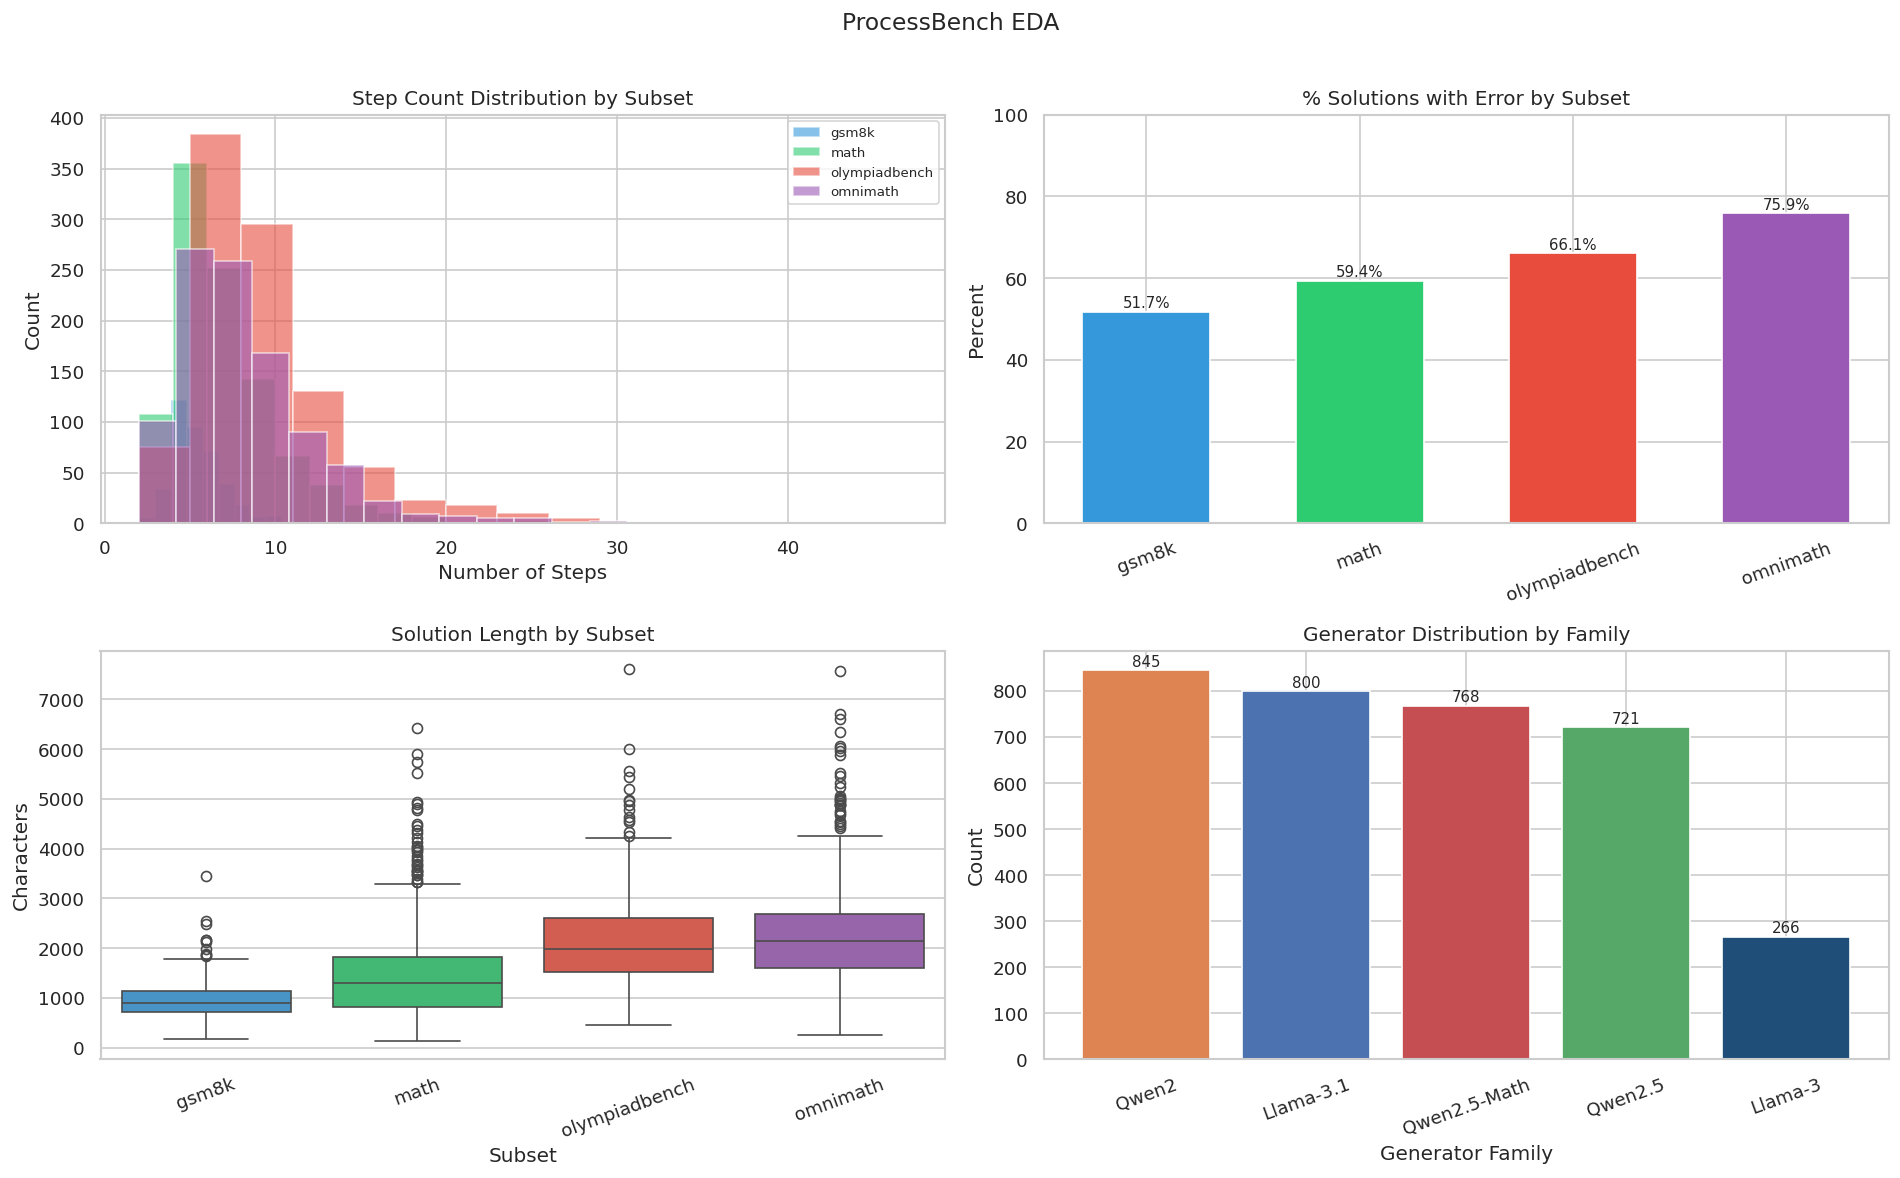

EDA figure saved.


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: Step count distribution
for subset in subsets_order:
    sub = df_eda[df_eda['subset'] == subset]
    axes[0, 0].hist(sub['n_steps'], bins=15, alpha=0.6,
                    color=subset_colors[subset], label=subset, edgecolor='white')
axes[0, 0].set_title('Step Count Distribution by Subset')
axes[0, 0].set_xlabel('Number of Steps')
axes[0, 0].set_ylabel('Count')
axes[0, 0].legend(fontsize=8)

# Panel 2: % error by subset
pct_error = df_eda.groupby('subset')['has_error'].mean().reindex(subsets_order) * 100
bars = axes[0, 1].bar(subsets_order, pct_error,
                      color=[subset_colors[s] for s in subsets_order],
                      edgecolor='white', width=0.6)
axes[0, 1].set_title('% Solutions with Error by Subset')
axes[0, 1].set_ylabel('Percent')
axes[0, 1].set_ylim(0, 100)
axes[0, 1].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, pct_error):
    axes[0, 1].text(bar.get_x() + bar.get_width() / 2, val + 1,
                    f'{val:.1f}%', ha='center', fontsize=9)

# Panel 3: Solution length boxplot
sns.boxplot(data=df_eda, x='subset', y='solution_len', order=subsets_order,
            palette=subset_colors, ax=axes[1, 0])
axes[1, 0].set_title('Solution Length by Subset')
axes[1, 0].set_xlabel('Subset')
axes[1, 0].set_ylabel('Characters')
axes[1, 0].tick_params(axis='x', rotation=20)

# Panel 4: Generator family bar chart
generator_summary = (
    pd.DataFrame.from_dict(GENERATOR_META, orient='index')
    .rename_axis('generator').reset_index()
)
generator_summary['count'] = generator_summary['generator'].map(counts).fillna(0).astype(int)
family_count_df = generator_summary.groupby('family', as_index=False)['count'].sum().sort_values('count', ascending=False)
family_color_map = {fam: GENERATOR_META[family_models[fam][0]]['color'] for fam in family_models}
bars = axes[1, 1].bar(family_count_df['family'], family_count_df['count'],
                      color=[family_color_map[f] for f in family_count_df['family']],
                      edgecolor='white')
axes[1, 1].set_title('Generator Distribution by Family')
axes[1, 1].set_xlabel('Generator Family')
axes[1, 1].set_ylabel('Count')
axes[1, 1].tick_params(axis='x', rotation=20)
for bar, val in zip(bars, family_count_df['count']):
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2,
                    val + max(family_count_df['count']) * 0.01,
                    f'{int(val)}', ha='center', fontsize=9)

plt.suptitle('ProcessBench EDA', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(os.path.join(RESULTS_DIR, '06_eda_combined.png'), bbox_inches='tight', dpi=120)
plt.show()
print('EDA figure saved.')

### 3.4 Generator × Subset × Error Group Heatmap

Visualises sample availability across the full stratification space before sampling. Reveals structural imbalance that constrains downstream sampling.

> **GenAI prompt used:** *"Create a seaborn heatmap showing sample counts for generator × (subset + correctness + error_group) combinations, with the category columns combined into a readable string."*

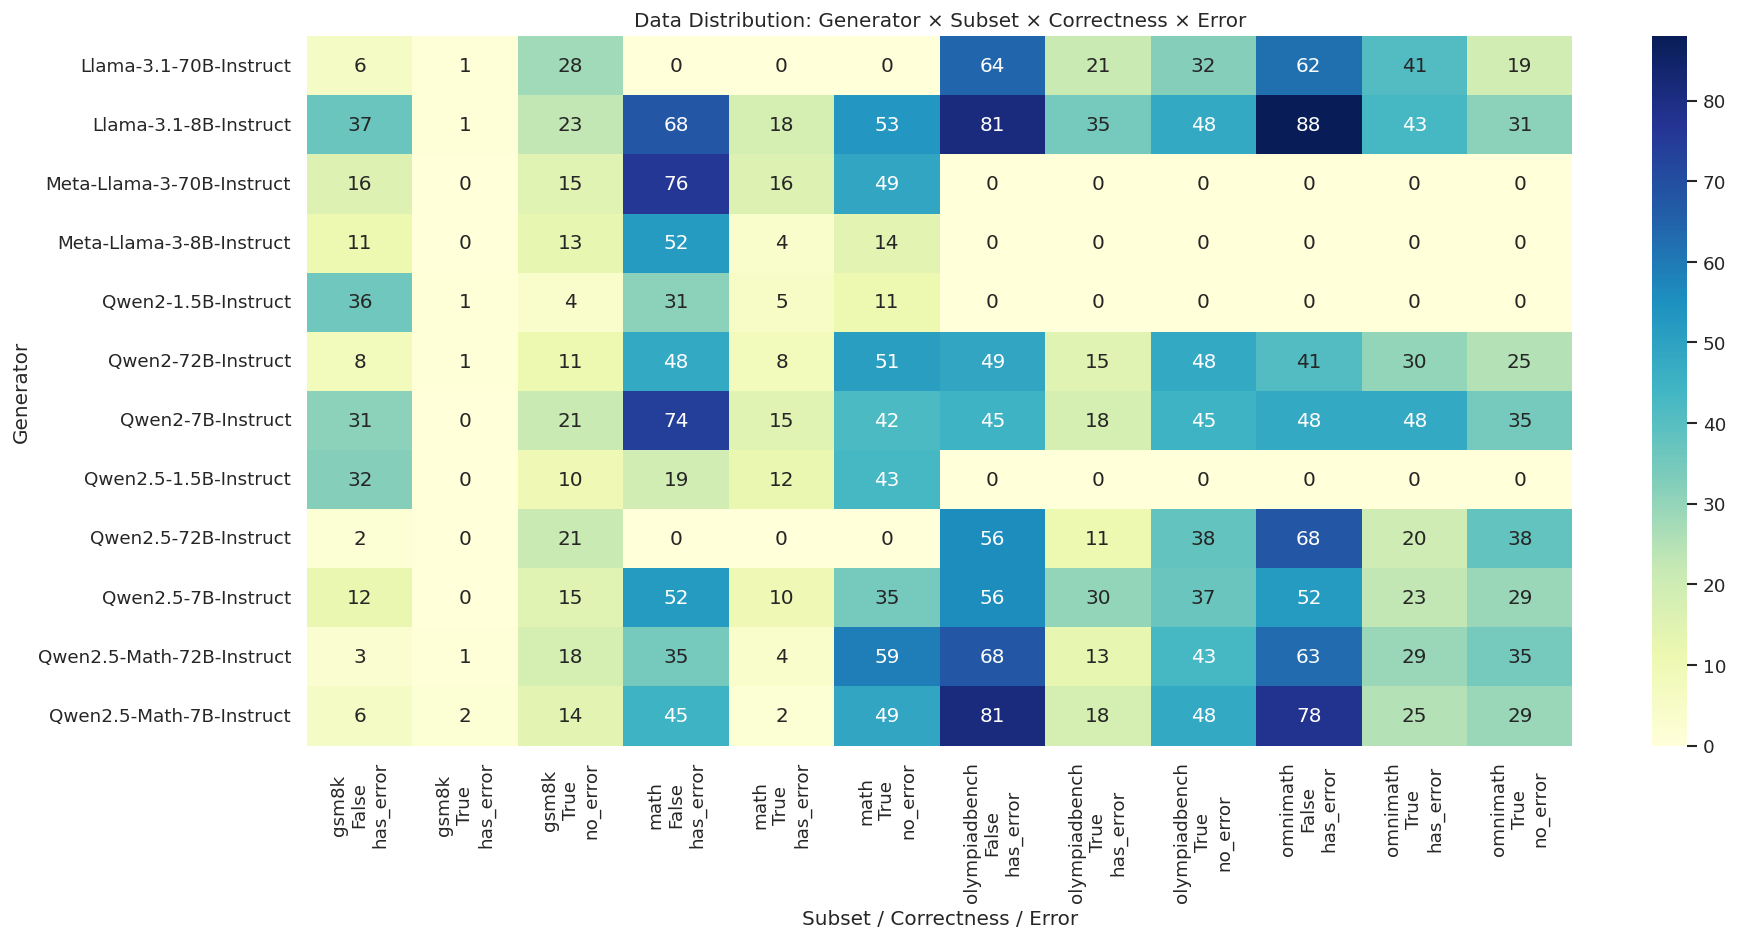

In [8]:
df_pb['error_group'] = df_pb['label'].apply(lambda x: 'no_error' if x == -1 else 'has_error')

df_counts = df_pb.groupby(['generator', 'subset', 'final_answer_correct', 'error_group']).size().reset_index(name='count')
df_counts['category'] = (df_counts['subset'] + '\n' +
                         df_counts['final_answer_correct'].astype(str) + '\n' +
                         df_counts['error_group'])
pivot = df_counts.pivot(index='generator', columns='category', values='count').fillna(0)

plt.figure(figsize=(16, 8))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Data Distribution: Generator × Subset × Correctness × Error')
plt.xlabel('Subset / Correctness / Error')
plt.ylabel('Generator')
plt.tight_layout()
plt.show()

#### Heatmap Interpretation — Generator × Subset × Error Group

Key observations from the stratification heatmap:

1. **Extreme imbalance** — GSM8K correct (no_error) samples: 0–2 per generator vs.
   OlympiadBench incorrect (has_error): 60–80. Not slightly imbalanced — orders of magnitude different.

2. **Structural missing data** — Some generators have entire zero columns for certain subsets
   (e.g., Meta-Llama-3-70B → olympiadbench = 0), meaning those combinations do not exist
   and cannot be balanced.

3. **Impact on metrics** — Generators with only 1 correct sample produce unstable FPR
   (0% or 100%), causing scatter plot collapse. Mixed together, this explains irregular
   appearances in downstream figures.


---

## 4. Stratified Sample Construction

A stratified sample is constructed to ensure balanced representation across all 4 difficulty subsets, both error groups (has_error, no_error), and all 12 generator models. N_PER_GROUP = 6 → target ~570 total samples.

> **GenAI prompt used:** *"Write a stratified sampling loop that iterates over generators × subsets × error groups, samples N_PER_GROUP rows from each, logs dropped groups where insufficient data exists, and concatenates results into df_sample."*

In [9]:
N_PER_GROUP = 6
rng = 42

frames = []
dropped_groups = []

for gen in sorted(df_pb['generator'].dropna().unique()):
    for subset in ['gsm8k', 'math', 'olympiadbench', 'omnimath']:
        sub = df_pb[(df_pb['generator'] == gen) & (df_pb['subset'] == subset)].copy()
        if len(sub) == 0:
            continue

        groups = {
            ('False', 'has_error'): sub[sub['final_answer_correct'] == False],
            ('True',  'has_error'): sub[(sub['final_answer_correct'] == True) & (sub['label'] >= 0)],
            ('True',  'no_error'):  sub[(sub['final_answer_correct'] == True) & (sub['label'] == -1)],
        }

        for (ans_key, err_key), part in groups.items():
            if len(part) < N_PER_GROUP:
                dropped_groups.append({
                    'generator': gen, 'subset': subset,
                    'final_answer_correct': ans_key, 'error_group': err_key,
                    'available': len(part), 'needed': N_PER_GROUP,
                })
                continue
            frames.append(part.sample(n=N_PER_GROUP, random_state=rng))

df_sample = pd.concat(frames).reset_index(drop=True)
df_sample['error_group'] = df_sample['label'].apply(lambda x: 'no_error' if x == -1 else 'has_error')
df_sample['n_steps']      = df_sample['steps'].apply(len)
df_sample['problem_len']  = df_sample['problem'].apply(len)
df_sample['solution_len'] = df_sample['steps'].apply(lambda x: sum(len(s) for s in x))

print(f'Sample size: {len(df_sample)} questions')
print(f'Estimated inference runtime: ~{len(df_sample) * 22 / 60:.0f} minutes')
print(df_sample['generator'].value_counts().to_string())

if dropped_groups:
    df_dropped = pd.DataFrame(dropped_groups)
    print('\nDropped incomplete groups:')
    print(df_dropped.to_string(index=False))

Sample size: 570 questions
Estimated inference runtime: ~209 minutes
generator
Llama-3.1-8B-Instruct        66
Qwen2.5-7B-Instruct          66
Qwen2-7B-Instruct            66
Qwen2-72B-Instruct           66
Qwen2.5-Math-7B-Instruct     60
Qwen2.5-Math-72B-Instruct    54
Llama-3.1-70B-Instruct       48
Qwen2.5-72B-Instruct         42
Qwen2.5-1.5B-Instruct        30
Meta-Llama-3-70B-Instruct    30
Meta-Llama-3-8B-Instruct     24
Qwen2-1.5B-Instruct          18

Dropped incomplete groups:
                generator subset final_answer_correct error_group  available  needed
   Llama-3.1-70B-Instruct  gsm8k                 True   has_error          1       6
    Llama-3.1-8B-Instruct  gsm8k                 True   has_error          1       6
Meta-Llama-3-70B-Instruct  gsm8k                 True   has_error          0       6
 Meta-Llama-3-8B-Instruct  gsm8k                 True   has_error          0       6
 Meta-Llama-3-8B-Instruct   math                 True   has_error          4       6

### 4.1 Validate Sample Coverage

Verify step and length stats per subset, and estimated runtime breakdown.

In [10]:
print('Step & length stats by subset:')
print(df_sample.groupby('subset')[['n_steps', 'problem_len', 'solution_len']].describe().round(1).to_string())

print('\nEstimated runtime by subset (~22s/question):')
for subset in ['gsm8k', 'math', 'olympiadbench', 'omnimath']:
    sub = df_sample[df_sample['subset'] == subset]
    print(f'  {subset:<15} {len(sub)} questions  avg_sol_len={sub["solution_len"].mean():.0f} chars  ~{len(sub)*22:.0f}s')

print(f'\nTotal estimated: ~{len(df_sample)*22/60:.1f} min')

Step & length stats by subset:
              n_steps                                      problem_len                                                  solution_len                                                      
                count mean  std  min  25%  50%   75%   max       count   mean    std   min    25%    50%    75%     max        count    mean    std    min     25%     50%     75%     max
subset                                                                                                                                                                                    
gsm8k           126.0  5.3  1.7  2.0  4.0  5.0   6.0  12.0       126.0  256.2  114.2  97.0  169.5  231.5  319.5   848.0        126.0   940.7  417.5  390.0   657.0   854.5  1148.0  3446.0
math            156.0  6.5  2.9  2.0  4.0  6.0   8.0  18.0       156.0  208.6  185.2  16.0  105.8  160.0  247.8  1167.0        156.0  1437.6  893.4  166.0   821.5  1294.0  1736.8  5519.0
olympiadbench   144.0  8.3  3.9  3

---

## 5. Save Sample to Parquet

Persist the stratified sample as a Parquet file in V1-data for consumption by Notebook 2 (analysis). This is the only data file produced by this notebook that Notebook 2 reads.

In [11]:
# Persist the stratified sample. If the file already exists in F-data/
# (it does, as part of this submission), prefer the frozen copy so the
# grader's downstream analysis is bit-identical to the author's.
if os.path.exists(SAMPLE_PATH):
    df_sample_on_disk = pd.read_parquet(SAMPLE_PATH)
    print(f'Existing stratified sample found: {len(df_sample_on_disk)} rows \u2192 {SAMPLE_PATH}')
    print('(Kept the frozen copy; the freshly-computed df_sample remains in memory for inspection.)')
else:
    df_sample.to_parquet(SAMPLE_PATH, index=False)
    print(f'Stratified sample saved: {len(df_sample)} rows \u2192 {SAMPLE_PATH}')

# Full ProcessBench is loaded from cache earlier; no need to re-write it here.
print(f'Full ProcessBench cached at {PARQUET_PATH} ({len(df_pb):,} rows)')

Existing stratified sample found: 570 rows → [private Drive path removed]
(Kept the frozen copy; the freshly-computed df_sample remains in memory for inspection.)
Full ProcessBench cached at [private Drive path removed]
